In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk

## Fetching census income data

In [ ]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
census_income_kdd = fetch_ucirepo(id=117) 
  
# data (as pandas dataframes) 
X = census_income_kdd.data.features 
y = census_income_kdd.data.targets 

X.drop(columns='MARSUPWRT', inplace=True)

# metadata 
print(census_income_kdd.metadata) 
  
# variable information 
print(census_income_kdd.variables) 

{'uci_id': 117, 'name': 'Census-Income (KDD)', 'repository_url': 'https://archive.ics.uci.edu/dataset/117/census+income+kdd', 'data_url': 'https://archive.ics.uci.edu/static/public/117/data.csv', 'abstract': 'This data set contains weighted census data extracted from the 1994 and 1995 current population surveys conducted by the U.S. Census Bureau.', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 299285, 'num_features': 41, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Education Level', 'Marital Status', 'Race', 'Sex', 'Other', 'Nationality', 'Income'], 'target_col': ['income'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2000, 'last_updated': 'Fri Mar 08 2024', 'dataset_doi': '10.24432/C5N30T', 'creators': [], 'intro_paper': None, 'additional_info': {'summary': "This data set contains weighted census data extracted from the 

In [78]:
X.head()

,AAGE,ACLSWKR,ADTINK,ADTOCC,AHGA,AHSCOL,AMARITL,AMJIND,AMJOCC,ARACE,...,PEFNTVTY,PEMNTVTY,PENATVTY,PRCITSHP,SEOTR,VETQVA,VETYN,WKSWORK,AHRSPAY,year
0,73,Not in universe,0,0,High school graduate,Not in universe,Widowed,Not in universe or children,Not in universe,White,...,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,2,0,0,95
1,58,Self-employed-not incorporated,4,34,Some college but no degree,Not in universe,Divorced,Construction,Precision production craft & repair,White,...,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,2,52,0,94
2,18,Not in universe,0,0,10th grade,High school,Never married,Not in universe or children,Not in universe,Asian or Pacific Islander,...,Vietnam,Vietnam,Vietnam,Foreign born- Not a citizen of U S,0,Not in universe,2,0,0,95
3,9,Not in universe,0,0,Children,Not in universe,Never married,Not in universe or children,Not in universe,White,...,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,0,0,0,94
4,10,Not in universe,0,0,Children,Not in universe,Never married,Not in universe or children,Not in universe,White,...,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,0,0,0,94


[9, 52, 47, 17, 3, 7, 24, 15, 5, 10, 3, 6, 8, 6, 6, 50, 38, 8, 9, 8, 9, 3, 3, 5, 42, 42, 42, 5, 3, 3, 3]


([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30],
 [Text(0, 0, 'ACLSWKR'),
  Text(1, 0, 'ADTINK'),
  Text(2, 0, 'ADTOCC'),
  Text(3, 0, 'AHGA'),
  Text(4, 0, 'AHSCOL'),
  Text(5, 0, 'AMARITL'),
  Text(6, 0, 'AMJIND'),
  Text(7, 0, 'AMJOCC'),
  Text(8, 0, 'ARACE'),
  Text(9, 0, 'AREORGN'),
  Text(10, 0, 'AUNMEM'),
  Text(11, 0, 'AUNTYPE'),
  Text(12, 0, 'AWKSTAT'),
  Text(13, 0, 'FILESTAT'),
  Text(14, 0, 'GRINREG'),
  Text(15, 0, 'GRINST'),
  Text(16, 0, 'HHDFMX'),
  Text(17, 0, 'HHDREL'),
  Text(18, 0, 'MIGMTR1'),
  Text(19, 0, 'MIGMTR3'),
  Text(20, 0, 'MIGMTR4'),
  Text(21, 0, 'MIGSAME'),
  Text(22, 0, 'MIGSUN'),
  Text(23, 0, 'PARENT'),
  Text(24, 0, 'PEFNTVTY'),
  Text(25, 0, 'PEMNTVTY'),
  Text(26, 0, 'PENATVTY'),
  Text(27, 0, 'PRCITSHP'),
  Text(28, 0, 'SEOTR'),
  Text(29, 0, 'VETQVA'),
  Text(30, 0, 'VETYN')])

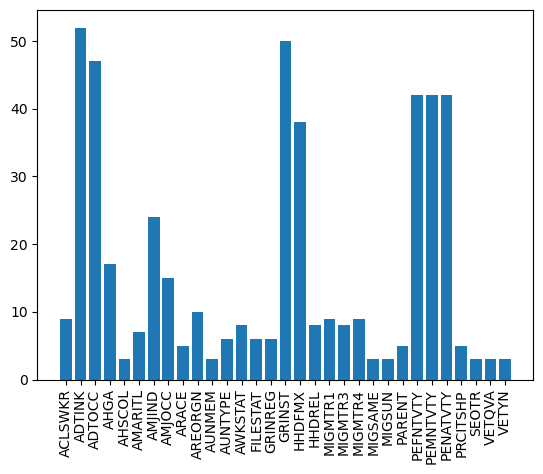

In [79]:
categorical_features = X.drop(columns=['ASEX', 'year', 'AAGE', 'CAPGAIN', 'GAPLOSS', 'DIVVAL', 'WKSWORK', 'AHRSPAY', 'NOEMP'])
feature_counts = []

for feature in categorical_features.columns:
    feature_counts.append(categorical_features[feature].value_counts().shape[0])
print(feature_counts)

plt.bar(categorical_features.columns, feature_counts)
plt.xticks(rotation=90)

## Formatting data

In [80]:
from sklearn.preprocessing import OrdinalEncoder

# Converting all categorical features to integer type through Ordinal Encoding for use in the Random Forest model
for feature in X.select_dtypes(include='object').columns:
    X[feature] = X[feature].astype(str).str.strip()

cat_features = X.select_dtypes(include='object').columns.tolist()

X[cat_features] = OrdinalEncoder().fit_transform(X[cat_features])
y.value_counts()

C:\Users\MarcAnthony\AppData\Local\Temp\ipykernel_31580\3858790750.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for feature in X.select_dtypes(include='object').columns:
C:\Users\MarcAnthony\AppData\Local\Temp\ipykernel_31580\3858790750.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/d

income  
-50000      187141
 50000+.     12382
Name: count, dtype: int64

In [81]:
from sklearn.preprocessing import LabelEncoder

# Converting the target variable to integer type through Label Encoding for use in the Random Forest model
y_new = LabelEncoder().fit_transform(y)
y = pd.Series(y_new, name='income')
y.value_counts()

c:\Users\MarcAnthony\anaconda3\envs\ML_env\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


income
1    187141
0     12382
Name: count, dtype: int64

In [82]:
X.head()

,AAGE,ACLSWKR,ADTINK,ADTOCC,AHGA,AHSCOL,AMARITL,AMJIND,AMJOCC,ARACE,...,PEFNTVTY,PEMNTVTY,PENATVTY,PRCITSHP,SEOTR,VETQVA,VETYN,WKSWORK,AHRSPAY,year
0,73,3.0,0,0,12.0,2.0,6.0,14.0,6.0,4.0,...,39.0,39.0,39.0,4.0,0,1.0,2,0,0,95
1,58,6.0,4,34,16.0,2.0,0.0,4.0,8.0,4.0,...,39.0,39.0,39.0,4.0,0,1.0,2,52,0,94
2,18,3.0,0,0,0.0,1.0,4.0,14.0,6.0,1.0,...,40.0,40.0,40.0,0.0,0,1.0,2,0,0,95
3,9,3.0,0,0,10.0,2.0,4.0,14.0,6.0,4.0,...,39.0,39.0,39.0,4.0,0,1.0,0,0,0,94
4,10,3.0,0,0,10.0,2.0,4.0,14.0,6.0,4.0,...,39.0,39.0,39.0,4.0,0,1.0,0,0,0,94


In [83]:
#Joining the features and target variable into a single dataset for easier handling of missing values
dataset = pd.concat([X, y], axis=1)
print(dataset.shape[0])
dataset.dropna(inplace=True)
print(dataset.shape[0])
dataset.shape[1]

199523
95130


41

## Balanced Bagging

In [ ]:
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

#Exctracting a validation set with 10% from each class
minCL = dataset[dataset['income'] == 0] #minCL = income >= 50K
majCL = dataset[dataset['income'] == 1] #majCL = income < 50K
X_minCL = minCL.drop('income', axis=1)
y_minCL = minCL['income']
X_majCL = majCL.drop('income', axis=1)
y_majCL = majCL['income']

X_RminCL, X_valid_min, y_RminCL, y_valid_minCL = train_test_split(X_minCL, y_minCL, test_size=0.1, random_state=42)
X_RmajCL, X_valid_maj, y_RmajCL, y_valid_majCL = train_test_split(X_majCL, y_majCL, test_size=0.1, random_state=42)
valid_minCL = pd.concat([X_valid_min, y_valid_minCL], axis=1) #10% of minority class
valid_majCL = pd.concat([X_valid_maj, y_valid_majCL], axis=1) #10% of majority class
validation = pd.concat([valid_minCL, valid_majCL], axis=0) #Validation set

RminCL = pd.concat([X_RminCL, y_RminCL], axis=1) #Remaining minority class after extracting validation set
RmajCL = pd.concat([X_RmajCL, y_RmajCL], axis=1) #Remaining majority class after extracting validation set
RD = pd.concat([RminCL, RmajCL], axis=0) #RD = Remaining Dataset after extracting validation set
X_RD = RD.drop('income', axis=1); y_RD = RD['income']
X_valid = validation.drop('income', axis=1); y_valid = validation['income']


In [ ]:
W = RandomForestClassifier(n_jobs=-1) # base esitmator for bagging
B = 51
bbc = BalancedBaggingClassifier(
    estimator=W,
    n_estimators=B, # bagging size
    bootstrap=False, # no extra resampling of RminCL
    sampling_strategy='majority',
    random_state=42,
    n_jobs=-1
)
bbc.fit(X_RD, y_RD)

# Step 5: bagged confusion matrix on VAL
y_pred = bbc.predict(X_valid)
cm = confusion_matrix(y_valid, y_pred, labels=[1,0], normalize='true')
test_bag_pmaj = cm[0, 0]
test_bag_pmin = cm[1, 1]
print(f"test.bag.pmaj = {test_bag_pmaj*100:.2f}%")
print(f"test.bag.pmin = {test_bag_pmin*100:.2f}%")

# Step 5 — training-set confusion matrix of bagW
y_pred_train = bbc.predict(X_RD)
cm_train = confusion_matrix(y_RD, y_pred_train, labels=[1, 0], normalize='true')
train_bag_pmaj = cm_train[0, 0]
train_bag_pmin = cm_train[1, 1]
print(f"train.bag.pmaj = {train_bag_pmaj*100:.2f}%")
print(f"train.bag.pmin = {train_bag_pmin*100:.2f}%")


test.bag.pmaj = 84.11%
test.bag.pmin = 88.69%
[[0.84106625 0.15893375]
 [0.11313869 0.88686131]]
train.bag.pmaj = 85.43%
train.bag.pmin = 99.98%


## Result Analysis

In [ ]:
# Getting percentage accuracies of each base estimator in the bagging ensemble on the validation set
test_pmin = []
test_pmaj = []
for estimator in bbc.estimators_:
    y_pred = estimator.predict(X_valid)
    cm = confusion_matrix(y_valid, y_pred, labels=[1,0], normalize='true')
    test_pmaj.append(cm[0, 0])
    test_pmin.append(cm[1, 1])


c:\Users\MarcAnthony\anaconda3\envs\ML_env\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\MarcAnthony\anaconda3\envs\ML_env\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\MarcAnthony\anaconda3\envs\ML_env\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\MarcAnthony\anaconda3\envs\ML_env\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\MarcAnthony\anaconda3\envs\ML_env\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without f

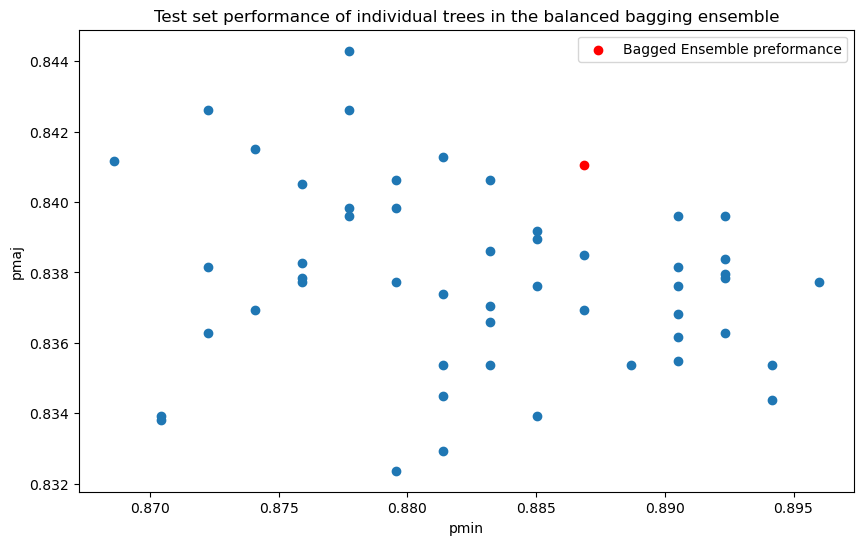

In [ ]:
# Plotting the performance of each base estimator in the bagging ensemble on the validation set, along with the overall performance of the bagged ensemble itself
fig = plt.figure(figsize=(10, 6))
plt.scatter(test_pmin, test_pmaj)
plt.scatter(test_bag_pmin, test_bag_pmaj, color='red', label='Bagged Ensemble preformance')
plt.xlabel('pmin'); plt.ylabel('pmaj')
plt.legend()
plt.title("Test set performance of individual trees in the balanced bagging ensemble")
plt.show()

## Hyper-paramerterization

In [ ]:
# Initializing parameters for hyperparameterization
params = {
    'n_estimators': 100,
    'min_samples_leaf': 1,
    'max_depth': None
}

# Hyperparameter options for tuning the Random Forest base estimator in the bagging ensemble
options = {
    'n_estimators': [100, 150, 200, 300],
    'min_samples_leaf': [1, 5, 10, 15, 20],
    "max_depth": [None, 10, 20, 30, 50, 75, 100]
}

In [ ]:
"NOTICE: this cell may take a while to run"


import time
B_values = [51, 101, 201, 301] # Hyperparameter options for tuning the bagging size
times = []

# Iterating through each parameter and its options, training a new model for each option, and evaluating its performance
for param in params:
    tbpmin_values = []
    tbpmaj_values = []

    for option in options[param]:
        print(f"Testing {param}: {option}")
        W = RandomForestClassifier(n_jobs=-1)

        W.set_params(**{k: v for k, v in params.items() if k != param}, **{param: option})
        model = BalancedBaggingClassifier(n_estimators=B,
                                          n_jobs=-1,
                                          random_state=42,
                                          bootstrap=False,
                                          sampling_strategy='majority',
                                          estimator=W)
        
        start_time = time.time()
        bbc = model.fit(X_RD, y_RD)

        cm = confusion_matrix(y_valid, bbc.predict(X_valid), labels=[1,0], normalize='true')
        tbpmaj = cm[0, 0]
        tbpmin = cm[1, 1]
        print(f"\t{option} test.bag.pmaj = {tbpmaj*100:.2f}%")
        print(f"\t{option} test.bag.pmin = {tbpmin*100:.2f}%")

        end_time = time.time()
        print(f"\t{option} time: {end_time - start_time:.2f} seconds")
        times.append(end_time - start_time)
        print("\n")

        tbpmaj_values.append(tbpmaj)
        tbpmin_values.append(tbpmin)

    score = np.array(tbpmin_values)
    best_idx = int(np.argmax(score))
    print(f"Best {param}: {options[param][best_idx]}  (score = {score[best_idx]:.4f})")
    params[param] = options[param][best_idx] # Updating parameter based on best preformance
    print("-" * 50)

tbpmin_values = []
tbpmaj_values = []

# Iterating through each bagging size option, training a new model for each option, and evaluating its performance
for B in B_values:
    print(f"Testing B = {B}")
    W = RandomForestClassifier(n_jobs=-1)
    W.set_params(**params)
    model = BalancedBaggingClassifier(n_jobs=-1,
                                      n_estimators=B,
                                      random_state=42,
                                      bootstrap=False,
                                      sampling_strategy='majority',
                                      estimator=W)
    
    
    start_time = time.time()
    bbc = model.fit(X_RD, y_RD)



    cm = confusion_matrix(y_valid, bbc.predict(X_valid), labels=[1,0], normalize='true')
    tbpmaj = cm[0, 0]
    tbpmin = cm[1, 1]
    print(f"\t{B} test.bag.pmaj = {tbpmaj*100:.2f}%")
    print(f"\t{B} test.bag.pmin = {tbpmin*100:.2f}%")

    end_time = time.time()
    print(f"\t{B} time: {end_time - start_time:.2f} seconds")
    times.append(end_time - start_time)
    print("\n")

    tbpmaj_values.append(tbpmaj)
    tbpmin_values.append(tbpmin)

score = np.array(tbpmin_values)
best_idx = int(np.argmax(score))
B = B_values[best_idx] # Updating bagging size based on best preformance
print(f"Best B: {B}  (score = {score[best_idx]:.4f})")

print(f"Total training time for all parameter combinations: {sum(times):.2f} seconds")

Testing n_estimators: 100
	100 test.bag.pmaj = 84.11%
	100 test.bag.pmin = 88.69%
	100 time: 30.16 seconds


Testing n_estimators: 150
	150 test.bag.pmaj = 84.11%
	150 test.bag.pmin = 88.50%
	150 time: 38.69 seconds


Testing n_estimators: 200
	200 test.bag.pmaj = 84.06%
	200 test.bag.pmin = 88.50%
	200 time: 55.73 seconds


Testing n_estimators: 300
	300 test.bag.pmaj = 84.10%
	300 test.bag.pmin = 88.50%
	300 time: 101.10 seconds


Best n_estimators: 100  (score = 0.8869)
--------------------------------------------------
Testing min_samples_leaf: 1
	1 test.bag.pmaj = 84.11%
	1 test.bag.pmin = 88.69%
	1 time: 32.18 seconds


Testing min_samples_leaf: 5
	5 test.bag.pmaj = 83.57%
	5 test.bag.pmin = 88.69%
	5 time: 12.98 seconds


Testing min_samples_leaf: 10
	10 test.bag.pmaj = 82.82%
	10 test.bag.pmin = 89.42%
	10 time: 7.96 seconds


Testing min_samples_leaf: 15
	15 test.bag.pmaj = 82.37%
	15 test.bag.pmin = 89.78%
	15 time: 6.92 seconds


Testing min_samples_leaf: 20
	20 test.bag.pma

In [55]:
params
B=51

In [88]:
# Final Random Forest base estimator with tuned hyperparameters
final_W = RandomForestClassifier(n_jobs=-1).set_params(**params) 
final_bbc = BalancedBaggingClassifier(n_estimators=B,
                                      n_jobs=-1,
                                      random_state=42,
                                      bootstrap=False,
                                      estimator=final_W)

final_bbc.fit(X_RD, y_RD)

# Getting percentage accuracies of the final bagged ensemble on the validation set
cm = confusion_matrix(y_valid, final_bbc.predict(X_valid), labels=[1,0], normalize='true')
final_bag_pmaj = cm[0, 0]
final_bag_pmin = cm[1, 1]
print(f"Final test.bag.pmaj = {final_bag_pmaj*100:.2f}%")
print(f"Final test.bag.pmin = {final_bag_pmin*100:.2f}%")


Final test.bag.pmaj = 81.04%
Final test.bag.pmin = 90.69%


## Balanced Random Forest Classifier

In [89]:
from imblearn.ensemble import BalancedRandomForestClassifier

# Training a new Random Forest model with the same tuned hyperparameters as the base estimator in the bagging ensemble for comparison
newRF = BalancedRandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).set_params(**params)
newRF.fit(X_RD, y_RD)

#Hard voting preformance on the validation set
cm = confusion_matrix(y_valid, newRF.predict(X_valid), labels=[1,0], normalize='true')
test_pmaj = cm[0, 0]
test_pmin = cm[1, 1]
print(f"test.pmaj = {test_pmaj*100:.2f}%")
print(f"test.pmin = {test_pmin*100:.2f}%")

test.pmaj = 81.60%
test.pmin = 90.33%


In [90]:
from sklearn.metrics import roc_curve, auc
#Soft voting preformance on the validation set

#Create AUC and ROC curve for the final model
y_pred_prob = final_bbc.predict_proba(X_valid)[:, 1]
fpr, tpr, thresholds = roc_curve(y_valid, y_pred_prob)
roc_auc = auc(fpr, tpr)

#CreateAUC and ROC curve for the new model
y_pred_prob_newRF = newRF.predict_proba(X_valid)[:, 1]
fpr_newRF, tpr_newRF, thresholds_newRF = roc_curve(y_valid, y_pred_prob_newRF)
roc_auc_newRF = auc(fpr_newRF, tpr_newRF)


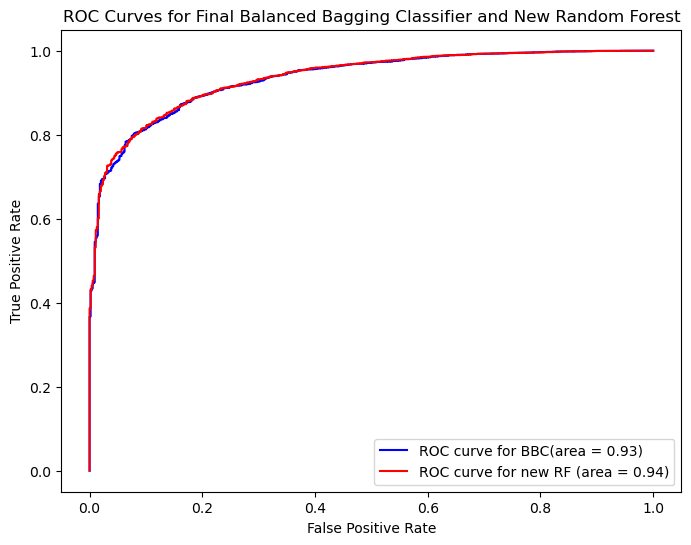

In [91]:
# Displaying the AUC and ROC curve for both the final bagged ensemble and the new Random Forest model for comparison
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve for BBC(area = {roc_auc:.2f})')
plt.plot(fpr_newRF, tpr_newRF, color='red', label=f'ROC curve for new RF (area = {roc_auc_newRF:.2f})')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend()
plt.title('ROC Curves for Final Balanced Bagging Classifier and New Random Forest')
plt.show()

## Enriching the minority class by SMOTE

In [96]:
from imblearn.over_sampling import SMOTENC
# Using SMOTENC to oversample the minority class in the remaining dataset after extracting the validation set for a new model training and comparison with the final bagged ensemble
resampler = SMOTENC(
    categorical_features=cat_features,   # column names of nominal features
    sampling_strategy=0.5, #imbalance rario after resampling
    k_neighbors=10,
    random_state=42,
)
resampled_X, resampled_y = resampler.fit_resample(X_RD, y_RD)
resampled_D = pd.concat([resampled_X, resampled_y], axis=1)

newRminCL = resampled_D[resampled_D['income'] == 0]
new_RD = pd.concat([newRminCL, RmajCL], axis=0)
newRD_X = new_RD.drop('income', axis=1)
newRD_y = new_RD['income']

print(f"newRminCL = {newRminCL.shape[0]}")
print(f"RminCL    = {RminCL.shape[0]}")
print(f"RmajCL    = {RmajCL.shape[0]}")

newRminCL = 40342
RminCL    = 4931
RmajCL    = 80685


In [97]:
# Training a new Random Forest model with the same tuned hyperparameters as the base estimator in the bagging ensemble on the new dataset with oversampled minority class for comparison
RF_star = newRF.fit(newRD_X, newRD_y)

# Getting percentage accuracies of the new Random Forest model on the validation set
cm = confusion_matrix(y_valid, RF_star.predict(X_valid), labels=[1,0], normalize='true')
test_pmaj = cm[0, 0]
test_pmin = cm[1, 1]
print(f"test.pmaj = {test_pmaj*100:.2f}%")
print(f"test.pmin = {test_pmin*100:.2f}%")

test.pmaj = 87.58%
test.pmin = 78.28%


In [98]:
# Creating AUC and ROC curve for oversampled model
RF_star_prob = RF_star.predict_proba(X_valid)[:, 1]
fpr_RF_star, tpr_RF_star, thresholds_RF_star = roc_curve(y_valid, RF_star_prob)
roc_auc_RF_star = auc(fpr_RF_star, tpr_RF_star)

Text(0.5, 1.0, 'ROC Curve for RF with SMOTENC vs New RF')

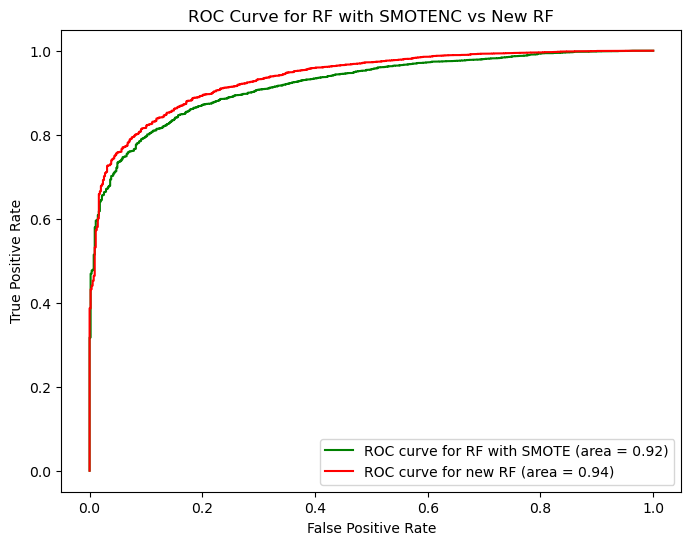

In [99]:
# Displaying the AUC and ROC curve for both the final bagged ensemble and the new Random Forest model trained on the oversampled dataset for comparison
plt.figure(figsize=(8, 6))
plt.plot(fpr_RF_star, tpr_RF_star, color='green', label=f'ROC curve for RF with SMOTE (area = {roc_auc_RF_star:.2f})')
plt.plot(fpr_newRF, tpr_newRF, color='red', label=f'ROC curve for new RF (area = {roc_auc_newRF:.2f})')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend()
plt.title('ROC Curve for RF with SMOTENC vs New RF')

In [102]:
from sklearn.ensemble import RandomForestClassifier
RF = RandomForestClassifier(n_jobs=-1).set_params(**params)
RF.fit(newRD_X, newRD_y)

cm = confusion_matrix(y_valid, RF.predict(X_valid), labels=[1,0], normalize='true')
test_pmaj = cm[0, 0]
test_pmin = cm[1, 1]
print(f"test.pmaj = {test_pmaj*100:.2f}%")
print(f"test.pmin = {test_pmin*100:.2f}%")

test.pmaj = 92.90%
test.pmin = 65.88%
